# **Exploratory Data Analysis (EDA) | MASSIVE-Agents**

---

**Project:** KP Agentic AI + LLM  
**Dataset:** `massive-full-converted-all-langs-with-id` · `en-US` & `id-ID`  

**Notes:** Seluruh analisis hanya membaca data dari folder `data/raw` tanpa mengubah atau menghapus isinya.

In [21]:
from __future__ import annotations

import hashlib
import itertools
import json
import platform
import re
import sys
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# KONFIGURASI — tidak mengubah dataset mentah
LANGUAGES = ("en-US", "id-ID")
DATASET_FOLDER = "massive-full-converted-all-langs-with-id"
PROJECT_ROOT_OVERRIDE = None  # contoh: Path(r"D:\KP-Agentic-AI")
RANDOM_SEED = 2026
TOP_N_FUNCTIONS = 15
SAMPLES_PER_LANGUAGE_FOR_REVIEW = 12

SOURCE_URL = "https://huggingface.co/datasets/AmazonScience/massive-agents"

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | matplotlib {plt.matplotlib.__version__}")
print("OS:", platform.system(), "| cwd:", Path.cwd())

Python 3.13.12 | pandas 3.0.6 | matplotlib 3.11.2
OS: Windows | cwd: d:\KP-Agentic-AI\notebooks


## **1 · Lokasi Project dan Sumber Data**

---

In [22]:
def find_project_root(override=None):
    candidates = [Path(override).expanduser()] if override else [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data" / "raw" / DATASET_FOLDER).is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Buka project KP-Agentic-AI di VS Code atau isi "
        "PROJECT_ROOT_OVERRIDE pada cell konfigurasi."
    )

PROJECT_ROOT = find_project_root(PROJECT_ROOT_OVERRIDE)
DATA_DIR = PROJECT_ROOT / "data" / "raw" / DATASET_FOLDER
OUTPUT_DIR = PROJECT_ROOT / "results" / "exploratory_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for lang in LANGUAGES:
    for name in ("input.jsonl", "golden.jsonl"):
        if not (DATA_DIR / lang / name).is_file():
            raise FileNotFoundError(f"File wajib tidak ada: {DATA_DIR / lang / name}")

def file_sha256(path, chunk_size=1024 * 1024):
    sha = hashlib.sha256()
    with path.open("rb") as stream:
        for piece in iter(lambda: stream.read(chunk_size), b""):
            sha.update(piece)
    return sha.hexdigest()

manifest_rows = []
for lang in LANGUAGES:
    for name in ("input.jsonl", "golden.jsonl"):
        fp = DATA_DIR / lang / name
        manifest_rows.append({"language_code": lang, "filename": name,
                              "size_mib": round(fp.stat().st_size / (1024 ** 2), 3),
                              "sha256": file_sha256(fp)})
manifest_df = pd.DataFrame(manifest_rows)
print("Project:", PROJECT_ROOT)
print("Sumber :", DATA_DIR)
print("Output :", OUTPUT_DIR)
display(manifest_df)

prior_manifest = PROJECT_ROOT / "results" / "data_inspection" / "file_manifest.csv"
if prior_manifest.is_file():
    prev = pd.read_csv(prior_manifest, dtype=str)
    if {"language_code", "filename", "sha256"}.issubset(prev.columns):
        check = manifest_df.merge(prev[["language_code", "filename", "sha256"]],
                                  on=["language_code", "filename"], how="left", suffixes=("_now", "_inspection"))
        check["same_hash"] = check["sha256_now"].eq(check["sha256_inspection"])
        display(check[["language_code", "filename", "same_hash"]])
        if not check["same_hash"].all():
            print("PERHATIAN: ada file yang berubah atau belum tercatat sejak Data Inspection!")
    else:
        print("Manifest inspeksi lama ada, tetapi kolomnya tidak cocok; cek manual.")
else:
    print("Manifest Data Inspection sebelumnya tidak ditemukan; hash sesi ini tetap disimpan.")

Project: D:\KP-Agentic-AI
Sumber : D:\KP-Agentic-AI\data\raw\massive-full-converted-all-langs-with-id
Output : D:\KP-Agentic-AI\results\exploratory_analysis


,language_code,filename,size_mib,sha256
0,en-US,input.jsonl,78.074,2a43ab25bec162ae5c77e340d7afe0cdafa3dcd8972ca3...
1,en-US,golden.jsonl,0.245,aa3d369cde3d1d92c6886644d49ac797f6cfaab46d3509...
2,id-ID,input.jsonl,53.400,588a109dddb83d2da9caadfe95a9415e33728353a3cb26...
3,id-ID,golden.jsonl,0.168,f7717e3edc3bda9b7843e62cdbc23d5f3b055542e6f2a1...


,language_code,filename,same_hash
0,en-US,input.jsonl,True
1,en-US,golden.jsonl,True
2,id-ID,input.jsonl,True
3,id-ID,golden.jsonl,True


## **2 · Membaca JSONL dan Menyiapkan Tabel Data**

---

Setiap baris `input.jsonl` dibaca sebagai satu data dan dicocokkan dengan `golden.jsonl` berdasarkan urutan baris. Data kemudian disusun dalam tabel agar lebih mudah dianalisis.

- `language_code` menunjukkan bahasa berdasarkan folder `en-US` atau `id-ID`, bukan dari kolom `language` yang berisi `Python`.
- `gt` berisi fungsi dan argumen yang menjadi jawaban acuan.
- Daftar fungsi yang tersedia dibedakan dari fungsi yang menjadi jawaban acuan.
- Informasi fungsi diringkas agar tabel tidak menyimpan definisi yang sama berulang kali.
- Data dengan format bermasalah dicatat untuk diperiksa sebelum analisis dilanjutkan.

In [23]:
def parse_json_or_none(line):
    if line is None or not line.strip():
        return None
    try:
        value = json.loads(line)
    except json.JSONDecodeError:
        return None
    return value if isinstance(value, dict) else None

def gt_signature(gt):
    """Representasi stabil untuk membandingkan GT termasuk nama fungsi dan semua argumen."""
    return json.dumps(gt, ensure_ascii=False, sort_keys=True, separators=(",", ":"))

def normalize_for_comparison(text):
    """Untuk pencarian calon duplikat SAJA, bukan preprocessing model."""
    return " ".join(text.split()).casefold()

WORD_PATTERN = re.compile(r"(?u)\b\w+(?:['’]\w+)*\b")
records = []
gt_occurrences = Counter()
file_problems = []
file_summary = Counter()
catalog_signatures = defaultdict(Counter)

for lang in LANGUAGES:
    input_path = DATA_DIR / lang / "input.jsonl"
    golden_path = DATA_DIR / lang / "golden.jsonl"
    with input_path.open("r", encoding="utf-8-sig") as fi, golden_path.open("r", encoding="utf-8-sig") as fg:
        for line_number, (input_line, golden_line) in enumerate(
            itertools.zip_longest(fi, fg), start=1
        ):
            file_summary[(lang, "input_lines")] += int(input_line is not None)
            file_summary[(lang, "golden_lines")] += int(golden_line is not None)
            entry = parse_json_or_none(input_line)
            golden = parse_json_or_none(golden_line)
            if entry is None:
                file_problems.append({"language_code": lang, "line_number": line_number,
                                      "problem": "invalid_or_missing_input_record"})
                continue
            if golden is None:
                file_problems.append({"language_code": lang, "line_number": line_number,
                                      "problem": "invalid_or_missing_golden_record"})
            gt = entry.get("gt")
            gt_valid = isinstance(gt, dict)
            if not gt_valid:
                file_problems.append({"language_code": lang, "line_number": line_number,
                                      "problem": "ground_truth_not_dictionary"})
            question = entry.get("question")
            text = question if isinstance(question, str) else ""
            functions = entry.get("function")
            candidate_names = [f.get("name") for f in functions
                               if isinstance(f, dict) and isinstance(f.get("name"), str)] if isinstance(functions, list) else []
            catalog_signatures[lang][tuple(sorted(candidate_names))] += 1
            gt_names = tuple(sorted(str(name) for name in gt)) if gt_valid else ()
            for name in gt_names:
                gt_occurrences[(lang, name)] += 1
            word_list = WORD_PATTERN.findall(text)
            record_id = entry.get("id")
            records.append({
                "language_code": lang,
                "line_number": line_number,
                "row_key": f"{lang}:{line_number:07d}",
                "record_id": "" if record_id is None else str(record_id),
                "question": text,
                "question_cmp": normalize_for_comparison(text),
                "question_char_count": len(text),
                "question_word_count": len(word_list),
                "test_category": str(entry.get("test_category", "<missing>")),
                "raw_language_field": str(entry.get("language", "<missing>")),
                "candidate_function_count": len(candidate_names),
                "gt_function_count": len(gt_names),
                "gt_names": "; ".join(gt_names),
                "gt_signature": gt_signature(gt) if gt_valid else "",
                "gt_is_dict": gt_valid,
                "input_golden_equal": gt == golden if (gt_valid and golden is not None) else False,
            })

eda_df = pd.DataFrame.from_records(records)
if eda_df.empty:
    raise RuntimeError("Tidak ada rekaman JSONL yang dapat dibaca.")
file_problems_df = pd.DataFrame(file_problems, columns=["language_code", "line_number", "problem"])
print("Total data yang terbaca:", len(eda_df))
display(eda_df.drop(columns=["gt_signature", "question_cmp", "question"]).head(5))
print("Masalah pembacaan/pasangan:", len(file_problems_df))
if not file_problems_df.empty:
    display(file_problems_df.head(20))
    print("WARNING: statistik hanya mencakup JSON valid; selesaikan masalah sumber sebelum menetapkan benchmark final.")

Total data yang terbaca: 3287


,language_code,line_number,row_key,record_id,question_char_count,question_word_count,test_category,raw_language_field,candidate_function_count,gt_function_count,gt_names,gt_is_dict,input_golden_equal
0,en-US,1,en-US:0000001,0,31,8,multiple_function,Python,55,1,alarm.set,True,True
1,en-US,2,en-US:0000002,3,5,1,multiple_function,Python,55,1,audio.volume_mute,True,True
2,en-US,3,en-US:0000003,8,19,5,multiple_function,Python,55,1,iot.hue_lightchange,True,True
3,en-US,4,en-US:0000004,14,27,5,multiple_function,Python,55,1,iot.hue_lighton,True,True
4,en-US,5,en-US:0000005,19,39,8,multiple_function,Python,55,1,iot.hue_lightoff,True,True


Masalah pembacaan/pasangan: 0


## **3 · Analisis Jumlah dan Karakteristik Dataset**

---

menganalisis jumlah data per bahasa, ID unik, kecocokan input dengan ground truth, panjang kalimat, dan jumlah fungsi target dalam setiap perintah.

Persentase dihitung berdasarkan jumlah data masing-masing bahasa agar hasil analisis lebih mudah dibandingkan. Perbedaan jumlah data Inggris dan Indonesia tidak langsung menunjukkan perbedaan performa model.

,language_code,records,unique_ids,unique_questions_exact,empty_questions,input_golden_mismatch_or_missing,unique_gt_functions,median_words,p95_words,mean_gt_function_count,multi_gt_rows
0,en-US,1952,1952,1949,0,0,55,6.0,12.0,1.0,0
1,id-ID,1335,1335,1309,0,0,55,6.0,11.0,1.0,0


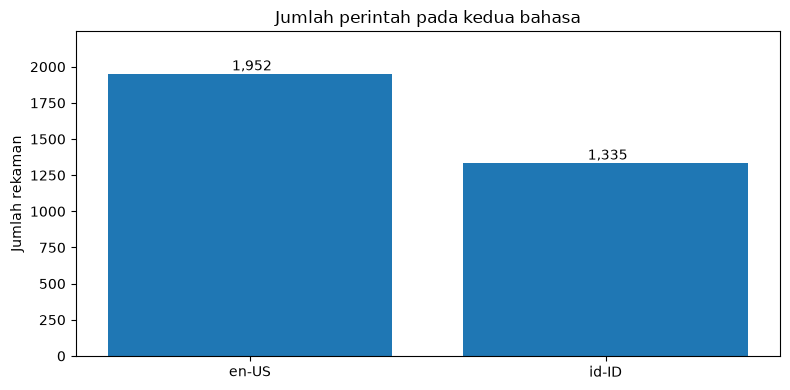

In [24]:
profile_rows=[]
for lang, sub in eda_df.groupby("language_code", sort=False):
    profile_rows.append({
        "language_code": lang,
        "records": len(sub),
        "unique_ids": int(sub.loc[sub.record_id.ne(""), "record_id"].nunique()),
        "unique_questions_exact": int(sub.question.nunique()),
        "empty_questions": int(sub.question.str.strip().eq("").sum()),
        "input_golden_mismatch_or_missing": int((~sub.input_golden_equal).sum()),
        "unique_gt_functions": len({name for (l,name) in gt_occurrences if l == lang}),
        "median_words": float(sub.question_word_count.median()),
        "p95_words": float(sub.question_word_count.quantile(.95)),
        "mean_gt_function_count": round(float(sub.gt_function_count.mean()),3),
        "multi_gt_rows": int(sub.gt_function_count.gt(1).sum()),
    })
profile_df = pd.DataFrame(profile_rows)
display(profile_df)

fig, ax=plt.subplots(figsize=(8,4))
vals=[int((eda_df.language_code == l).sum()) for l in LANGUAGES]
ax.bar(list(LANGUAGES), vals)
for idx,value in enumerate(vals):
    ax.text(idx, value, f" {value:,}", ha="center", va="bottom")
ax.set_title("Jumlah perintah pada kedua bahasa")
ax.set_ylabel("Jumlah rekaman")
ax.set_ylim(0, max(vals)*1.15 if max(vals) else 1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "records_by_language.png", dpi=180)
plt.show(); plt.close(fig)

## **4 · Analisis Kategori Pengujian dan Jumlah Fungsi**

---

Label `multiple_function` tidak selalu berarti satu perintah memiliki lebih dari satu fungsi target. Kategori ini juga bukan penanda bahasa formal, informal, atau slang.

,language_code,test_category,count
0,en-US,multiple_function,1952
1,id-ID,multiple_function,1335


,language_code,gt_function_count,count,percent_in_language
0,en-US,1,1952,100.0
1,id-ID,1,1335,100.0


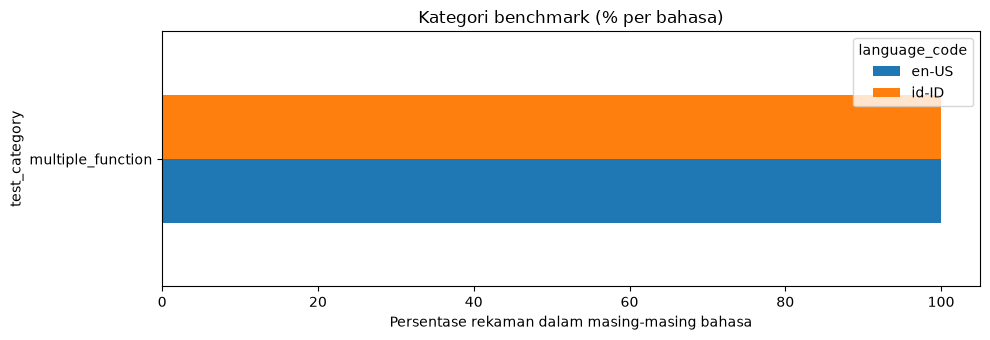

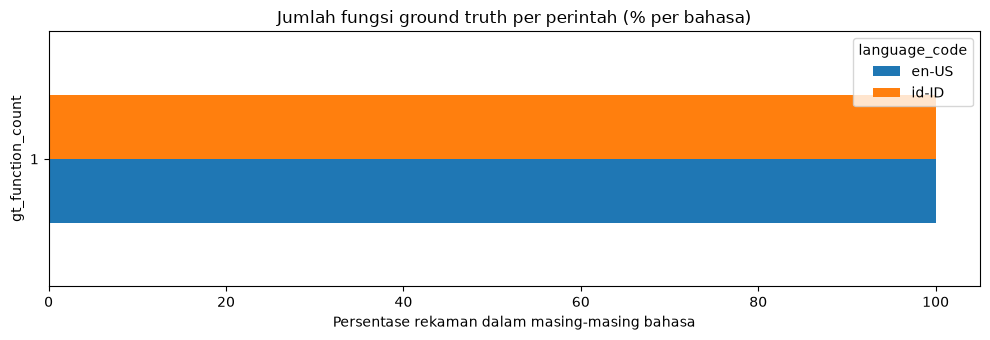

In [25]:
category_counts=(eda_df.groupby(["language_code", "test_category"])
                 .size().rename("count").reset_index())
display(category_counts.sort_values(["language_code", "count"], ascending=[True,False]))
call_counts=(eda_df.groupby(["language_code", "gt_function_count"])
             .size().rename("count").reset_index())
call_counts["percent_in_language"]=(call_counts["count"] /
    call_counts.groupby("language_code")["count"].transform("sum") * 100).round(2)
display(call_counts)

for field,label,filename in [
    ("test_category", "Kategori benchmark", "benchmark_categories.png"),
    ("gt_function_count", "Jumlah fungsi ground truth per perintah", "gt_calls_per_record.png"),
]:
    pivot=pd.crosstab(eda_df[field], eda_df.language_code, normalize="columns")*100
    pivot=pivot.reindex(columns=LANGUAGES, fill_value=0)
    fig,ax=plt.subplots(figsize=(10,max(3.5,len(pivot)*0.48)))
    pivot.plot(kind="barh",ax=ax)
    ax.set_title(label + " (% per bahasa)")
    ax.set_xlabel("Persentase rekaman dalam masing-masing bahasa")
    ax.set_ylabel(field)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename,dpi=170,bbox_inches="tight")
    plt.show();plt.close(fig)

## **5 · Analisis Panjang dan Pola Penulisan Teks**

---

Jumlah kata dihitung menggunakan regex, bukan tokenizer LLM. Grafik digunakan untuk melihat pola dan menemukan kalimat yang terlalu panjang atau berbeda dari kebanyakan data, bukan untuk menentukan bahasa mana yang lebih sulit.

,language_code,metric,min,mean,median,p90,p95,max
0,en-US,question_word_count,1,6.74,6.0,10.0,12.0,33
1,en-US,question_char_count,5,34.09,32.0,53.0,59.0,160
2,id-ID,question_word_count,1,6.13,6.0,10.0,11.0,26
3,id-ID,question_char_count,4,37.10,34.0,59.0,67.0,153


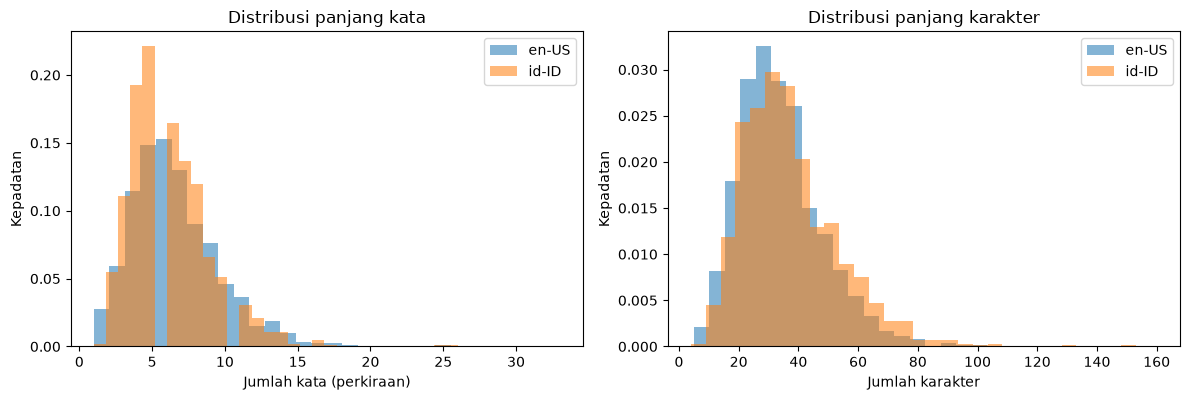

Contoh 5 perintah terpanjang (berdasarkan jumlah kata) tiap bahasa:

 en-US


,record_id,question_word_count,question_char_count,question
1743,14838,33,160,what is a neutral density filter and would i w...
925,7712,25,124,hey olly cancel all my other meetings and call...
1645,14026,25,114,if a pencil cost four dollars and a book ten d...
924,7711,24,119,hey cancel all my other meetings and calls for...
591,4544,19,103,order a twelve piece honey mustard wing combo ...



 id-ID


,record_id,question_word_count,question_char_count,question
2590,7712,26,153,hei olly batalkan semua rapat dan panggilan sa...
3054,14026,25,133,kalau harga satu pensil dua ribu rupiah dan ha...
2170,2447,17,105,saya ingin sup untuk makan siang pesan dari re...
2995,13411,16,93,tunjukkan jawaban dari soal ini dua ratus empa...
2683,9110,16,92,pameran misa dua ribu tujuh belas pada dua pul...


In [26]:
length_rows=[]
for lang,sub in eda_df.groupby("language_code",sort=False):
    for field in ("question_word_count", "question_char_count"):
        series=sub[field]
        length_rows.append({"language_code":lang,"metric":field,
                            "min":int(series.min()),"mean":round(float(series.mean()),2),
                            "median":round(float(series.median()),2),
                            "p90":round(float(series.quantile(.90)),2),
                            "p95":round(float(series.quantile(.95)),2),
                            "max":int(series.max())})
length_df=pd.DataFrame(length_rows)
display(length_df)

fig,axes=plt.subplots(1,2,figsize=(12,4.1))
for lang in LANGUAGES:
    sub=eda_df.loc[eda_df.language_code.eq(lang)]
    axes[0].hist(sub.question_word_count,bins=30,alpha=.55,label=lang,density=True)
    axes[1].hist(sub.question_char_count,bins=30,alpha=.55,label=lang,density=True)
axes[0].set(xlabel="Jumlah kata (perkiraan)",ylabel="Kepadatan",title="Distribusi panjang kata")
axes[1].set(xlabel="Jumlah karakter",ylabel="Kepadatan",title="Distribusi panjang karakter")
for ax in axes:ax.legend()
fig.tight_layout();fig.savefig(OUTPUT_DIR / "text_lengths.png",dpi=180)
plt.show();plt.close(fig)

print("Contoh 5 perintah terpanjang (berdasarkan jumlah kata) tiap bahasa:")
for lang in LANGUAGES:
    print("\n",lang)
    display(eda_df.loc[eda_df.language_code.eq(lang),
           ["record_id","question_word_count","question_char_count","question"]]
           .sort_values("question_word_count",ascending=False).head(5))

## **6 · Analisis Distribusi Fungsi dan Domain**

---

Domain ditentukan dari nama fungsi, misalnya `alarm.set` termasuk domain `alarm`, bukan berdasarkan label domain resmi.

Hasil analisis digunakan untuk melihat keseimbangan jumlah data per fungsi dan menjadi pertimbangan dalam pembagian dataset pada tahap berikutnya.

,language_code,unique_functions,function_occurrences,functions_below_5_occurrences,functions_below_10_occurrences,top_5_share_of_occurrences_pct
0,en-US,55,1952,3,7,30.02
1,id-ID,55,1335,4,12,31.31



Fungsi teratas: en-US


,function_name,gt_occurrences,pct_of_records
27,calendar.set,138,7.07
16,play.music,121,6.20
29,qa.factoid,120,6.15
12,weather.query,106,5.43
31,calendar.query,101,5.17
52,email.query,93,4.76
15,news.query,92,4.71
5,datetime.query,61,3.12
33,calendar.remove,56,2.87
35,play.radio,55,2.82


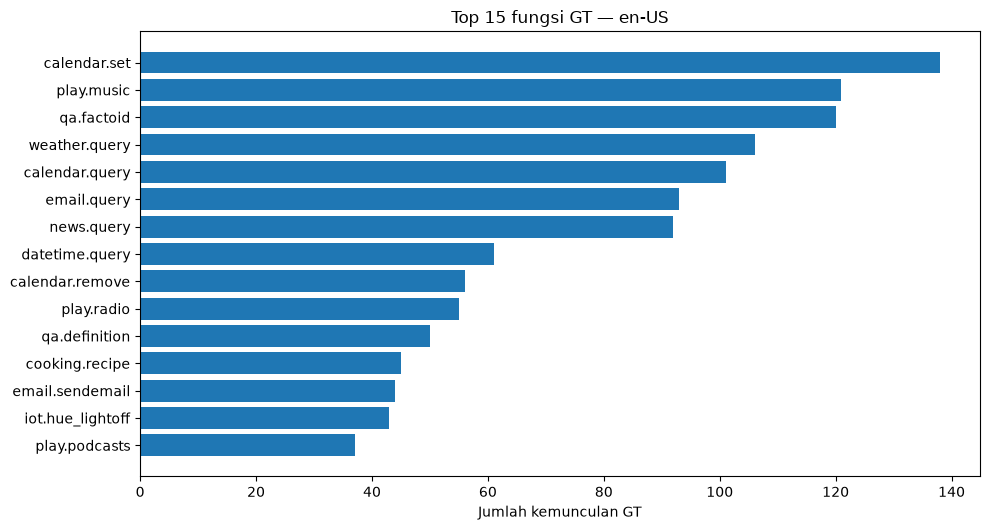


Fungsi teratas: id-ID


,function_name,gt_occurrences,pct_of_records
81,calendar.set,94,7.04
69,play.music,92,6.89
83,qa.factoid,86,6.44
107,email.query,75,5.62
65,weather.query,71,5.32
86,calendar.query,61,4.57
60,datetime.query,48,3.60
68,news.query,46,3.45
88,play.radio,43,3.22
85,calendar.remove,37,2.77


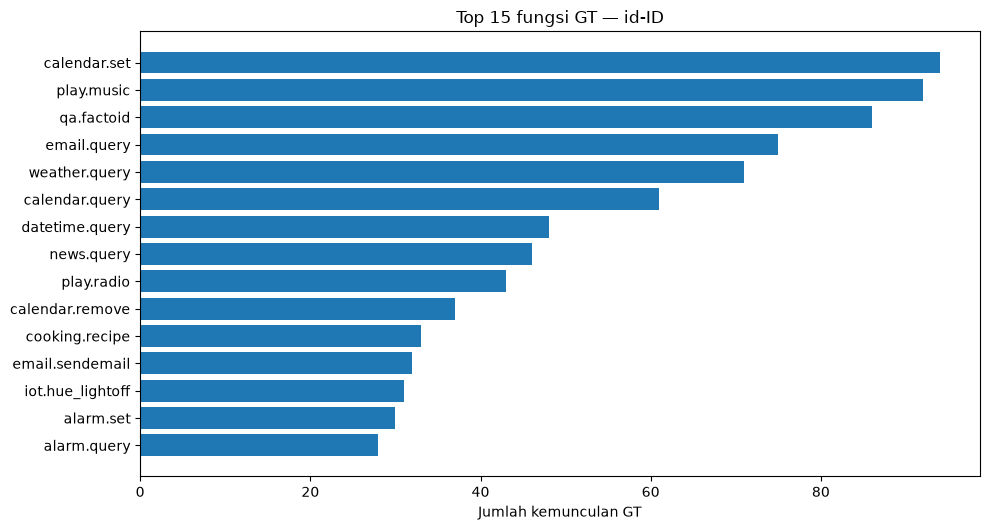

language_code,en-US,id-ID
domain_prefix,,
calendar,15.11,14.38
play,14.29,15.21
qa,12.45,12.66
iot,10.14,8.01
email,8.15,9.51
weather,5.43,5.32
transport,4.82,3.00
news,4.71,3.45
alarm,3.79,5.47


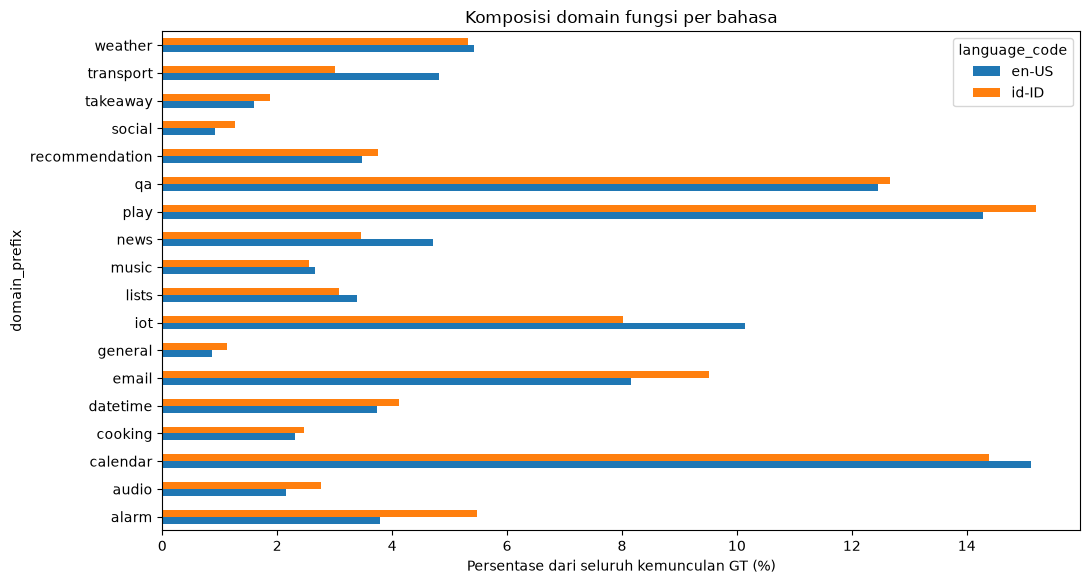

In [27]:
function_df=pd.DataFrame([
    {"language_code":lang,"function_name":name,"gt_occurrences":n,
     "domain_prefix":name.split(".",1)[0]}
    for (lang,name),n in gt_occurrences.items()
],columns=["language_code","function_name","gt_occurrences","domain_prefix"])
function_df["pct_of_records"]=function_df.apply(
    lambda r:round(100*r.gt_occurrences/max(1,int((eda_df.language_code==r.language_code).sum())),2),axis=1
)

summary_fn=[]
for lang in LANGUAGES:
    sub=function_df.loc[function_df.language_code.eq(lang)]
    total_occ=int(sub.gt_occurrences.sum())
    summary_fn.append({"language_code":lang,"unique_functions":len(sub),
                       "function_occurrences":total_occ,
                       "functions_below_5_occurrences":int(sub.gt_occurrences.lt(5).sum()),
                       "functions_below_10_occurrences":int(sub.gt_occurrences.lt(10).sum()),
                       "top_5_share_of_occurrences_pct":round(100*sub.nlargest(5,"gt_occurrences").gt_occurrences.sum()/max(1,total_occ),2)})
function_summary_df=pd.DataFrame(summary_fn)
display(function_summary_df)

for lang in LANGUAGES:
    top=function_df.loc[function_df.language_code.eq(lang)].nlargest(TOP_N_FUNCTIONS,"gt_occurrences")
    print(f"\nFungsi teratas: {lang}")
    display(top[["function_name","gt_occurrences","pct_of_records"]])
    fig,ax=plt.subplots(figsize=(10,max(4,len(top)*.36)))
    ax.barh(top.function_name.iloc[::-1],top.gt_occurrences.iloc[::-1])
    ax.set(xlabel="Jumlah kemunculan GT",title=f"Top {TOP_N_FUNCTIONS} fungsi GT — {lang}")
    fig.tight_layout();fig.savefig(OUTPUT_DIR / f"top_gt_functions_{lang}.png",dpi=180,bbox_inches="tight")
    plt.show();plt.close(fig)

# Perbandingan domain: % dari kemunculan fungsi GT, bukan persentase record.
domains=(function_df.groupby(["language_code","domain_prefix"],as_index=False)
         .agg(gt_occurrences=("gt_occurrences","sum")))
domains["percent_of_calls"]=(domains.gt_occurrences/
    domains.groupby("language_code").gt_occurrences.transform("sum")*100).round(2)
domain_pivot=domains.pivot(index="domain_prefix",columns="language_code",values="percent_of_calls")
domain_pivot=domain_pivot.reindex(columns=LANGUAGES).fillna(0)
display(domain_pivot.sort_values(LANGUAGES[0],ascending=False).head(20))
fig,ax=plt.subplots(figsize=(11,max(5,.33*len(domain_pivot))))
domain_pivot.plot(kind="barh",ax=ax)
ax.set(xlabel="Persentase dari seluruh kemunculan GT (%)",title="Komposisi domain fungsi per bahasa")
fig.tight_layout();fig.savefig(OUTPUT_DIR / "domain_composition.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)

## **7 · Analisis Kosakata dan Ciri Bahasa Informal**

---

Kata-kata umum (stopwords) tetap dihitung tanpa mengubah teks asli. Perbedaan jumlah kosakata antara Bahasa Inggris dan Indonesia tidak langsung menunjukkan bahwa salah satu bahasa lebih beragam karena jumlah datanya berbeda.

In [28]:
word_frequency=defaultdict(Counter)
lexical_rows=[]
for lang,sub in eda_df.groupby("language_code",sort=False):
    for q in sub.question:
        tokens=[tok.casefold() for tok in WORD_PATTERN.findall(q)]
        word_frequency[lang].update(tokens)
    lexical_rows.append({"language_code":lang,
                         "word_occurrences":sum(word_frequency[lang].values()),
                         "unique_word_forms":len(word_frequency[lang]),
                         "hapax_word_forms":sum(n==1 for n in word_frequency[lang].values())})
lexical_df=pd.DataFrame(lexical_rows)
display(lexical_df)
for lang in LANGUAGES:
    print(f"\nKata paling sering muncul — {lang}:")
    display(pd.DataFrame(word_frequency[lang].most_common(20),columns=["token","occurrences"]))

,language_code,word_occurrences,unique_word_forms,hapax_word_forms
0,en-US,13148,1915,1060
1,id-ID,8184,1526,831



Kata paling sering muncul — en-US:


,token,occurrences
0,the,737
1,to,326
2,me,318
3,is,316
4,what,281
5,my,261
6,for,240
7,i,237
8,a,234
9,in,217



Kata paling sering muncul — id-ID:


,token,occurrences
0,saya,429
1,di,233
2,yang,180
3,ini,164
4,apa,156
5,untuk,130
6,hari,114
7,berapa,112
8,jam,107
9,dari,106



## **8 · Analisis Awal Variasi Bahasa Informal**

---

Dataset belum memiliki label formal, informal, slang, dan typo yang sudah tervalidasi. Oleh karena itu, analisis ini menggunakan aturan sederhana (heuristik) untuk menemukan kemungkinan variasi bahasa yang perlu diperiksa lebih lanjut.

- Daftar kata informal dan singkatan hanya digunakan sebagai indikator awal, sehingga belum mencakup seluruh variasi bahasa.
- Penggunaan *contraction* seperti `don't` tidak selalu menunjukkan slang.
- Tanda baca berulang, emoji, dan pengulangan huruf dapat menjadi ciri bahasa informal, tetapi belum tentu merupakan typo.
- Typo belum dapat dipastikan hanya melalui pemeriksaan otomatis dan memerlukan validasi lebih lanjut.
- Hasil deteksi belum menunjukkan jumlah sebenarnya dari setiap variasi bahasa karena belum diverifikasi melalui anotasi manual.


,language_code,candidate_signal,count,percent_in_language
0,en-US,lexicon_candidate,0,0.00
1,en-US,english_contraction_candidate,172,8.81
2,en-US,repeated_punctuation,0,0.00
3,en-US,repeated_character,0,0.00
4,en-US,pictographic_symbol,0,0.00
5,en-US,contains_digit,0,0.00
6,id-ID,lexicon_candidate,1,0.07
7,id-ID,english_contraction_candidate,0,0.00
8,id-ID,repeated_punctuation,0,0.00
9,id-ID,repeated_character,0,0.00


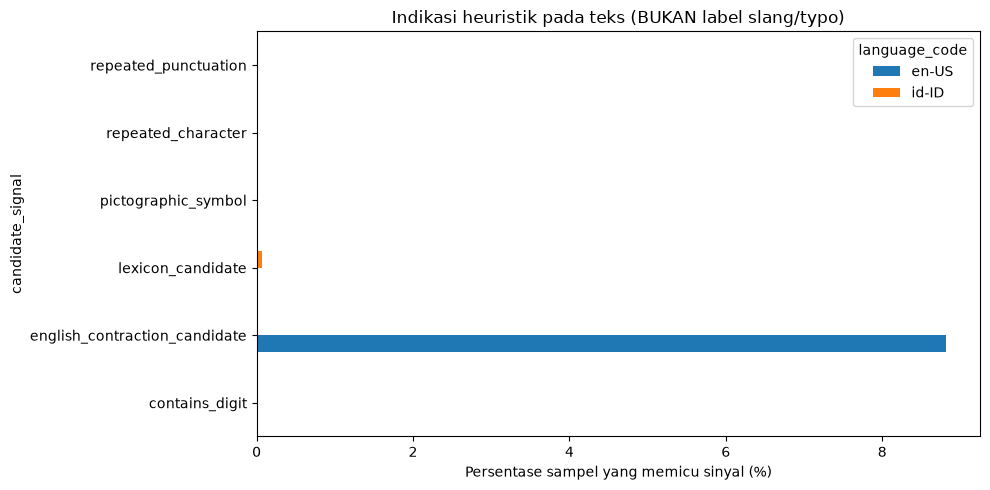

Contoh kandidat leksem slang/singkatan (MAKSIMAL 10 per bahasa, perlu validasi manual):

 en-US : 0 contoh yang ditampilkan

 id-ID : 1 contoh yang ditampilkan


,record_id,question,lexicon_hits
2982,13154,kamu tahu nomor h. p. jessica iskandar gak,gak


In [29]:
EN_TERMS={"gonna","wanna","gotta","lemme","ain't","pls","plz","thx",
          "tmrw","rn","btw","idk","lol","omg","y'all","cuz","ur"}
ID_TERMS={"gue","gw","gua","lu","lo","elo","gak","ga","nggak","ngga",
          "gk","bgt","yg","dgn","tdk","makasih","dong","nih","kuy","gimana"}
CONTRACTION_RE=re.compile(r"(?i)\b\w+(?:n't|'re|'ve|'ll|'d|'m|'s)\b")
REPEAT_PUNCT_RE=re.compile(r"[!?]{2,}|\.{3,}")
REPEAT_CHAR_RE=re.compile(r"(?iu)(\w)\1{2,}")
# Rentang ilustratif karakter pictographic; bukan parser emoji lengkap.
SYMBOL_RE=re.compile(r"[\U0001F300-\U0001FAFF]")

signal_rows=[]
for row in eda_df.itertuples(index=False):
    toks={t.casefold() for t in WORD_PATTERN.findall(row.question)}
    hits=sorted(toks & (EN_TERMS if row.language_code=="en-US" else ID_TERMS))
    signal_rows.append({
        "row_key":row.row_key,
        "lexicon_hits":"; ".join(hits),
        "lexicon_candidate":bool(hits),
        "english_contraction_candidate":bool(CONTRACTION_RE.search(row.question)) if row.language_code=="en-US" else False,
        "repeated_punctuation":bool(REPEAT_PUNCT_RE.search(row.question)),
        "repeated_character":bool(REPEAT_CHAR_RE.search(row.question)),
        "pictographic_symbol":bool(SYMBOL_RE.search(row.question)),
        "contains_digit":any(c.isdigit() for c in row.question),
    })
signal_df=pd.DataFrame(signal_rows)
eda_df=eda_df.merge(signal_df,on="row_key",how="left",validate="one_to_one")
signal_cols=["lexicon_candidate","english_contraction_candidate","repeated_punctuation",
             "repeated_character","pictographic_symbol","contains_digit"]
signal_summary=[]
for lang,sub in eda_df.groupby("language_code",sort=False):
    for signal in signal_cols:
        signal_summary.append({"language_code":lang,"candidate_signal":signal,
                               "count":int(sub[signal].sum()),
                               "percent_in_language":round(100*sub[signal].mean(),2)})
signal_summary_df=pd.DataFrame(signal_summary)
display(signal_summary_df)

signal_pivot=signal_summary_df.pivot(index="candidate_signal",columns="language_code",values="percent_in_language")
signal_pivot=signal_pivot.reindex(columns=LANGUAGES).fillna(0)
fig,ax=plt.subplots(figsize=(10,5))
signal_pivot.plot(kind="barh",ax=ax)
ax.set(xlabel="Persentase sampel yang memicu sinyal (%)",title="Indikasi heuristik pada teks (BUKAN label slang/typo)")
fig.tight_layout();fig.savefig(OUTPUT_DIR / "language_signals_candidates.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)

print("Contoh kandidat leksem slang/singkatan (MAKSIMAL 10 per bahasa, perlu validasi manual):")
for lang in LANGUAGES:
    sample=eda_df.loc[eda_df.language_code.eq(lang)&eda_df.lexicon_candidate,
                      ["record_id","question","lexicon_hits"]].head(10)
    print("\n",lang,":",len(sample),"contoh yang ditampilkan")
    if not sample.empty: display(sample)


## **9 · Analisis Duplikasi Data**

---

Setiap data duplikat diperiksa berdasarkan kesamaan teks, fungsi, dan argumen dalam `gt`. Perbedaan ground truth belum tentu menunjukkan kesalahan anotasi, sehingga data perlu diperiksa lebih lanjut dan tidak langsung dihapus.


In [30]:
def find_duplicate_groups(key):
    grouped=(eda_df.loc[eda_df[key].str.len().gt(0)]
             .groupby(["language_code",key],sort=True)
             .agg(occurrences=("row_key","size"),
                  unique_full_gt=("gt_signature","nunique"),
                  unique_function_sets=("gt_names","nunique"),
                  record_ids=("record_id",lambda s:"; ".join(s)),
                  example_question=("question","first"),
                  row_keys=("row_key",lambda s:"; ".join(s)))
             .reset_index())
    return grouped.loc[grouped.occurrences.gt(1)].sort_values(
        ["language_code","occurrences"],ascending=[True,False])

dup_exact_df=find_duplicate_groups("question")
dup_normalized_df=find_duplicate_groups("question_cmp")

for label,frame in [("Teks identik",dup_exact_df),("Case/spasi diabaikan",dup_normalized_df)]:
    print(f"\n{label}: {len(frame)} grup; "
          f"{int((frame.occurrences-1).sum()) if len(frame) else 0} baris ekstra")
    if not frame.empty:
        display(frame[["language_code","occurrences","unique_full_gt",
                       "unique_function_sets","record_ids","example_question"]].head(25))

conflicting_dup_df=dup_normalized_df.loc[dup_normalized_df.unique_full_gt.gt(1)].copy()
print("\nGrup pertanyaan identik (abaikan case/spasi) dengan GT LENGKAP berbeda:",len(conflicting_dup_df))
if not conflicting_dup_df.empty:
    display(conflicting_dup_df[["language_code","record_ids","example_question","unique_full_gt"]].head(20))
    # Bandingkan argumen GT per baris secara langsung dari signature tersimpan.
    for group in conflicting_dup_df.head(5).itertuples(index=False):
        mask=(eda_df.language_code.eq(group.language_code)&eda_df.question_cmp.eq(group.question_cmp))
        display(eda_df.loc[mask,["record_id","question","gt_names","gt_signature"]])


Teks identik: 22 grup; 29 baris ekstra


,language_code,occurrences,unique_full_gt,unique_function_sets,record_ids,example_question
599,en-US,2,1,1,12606; 12607,i need to get a ticket via train to orlando fr...
1815,en-US,2,1,1,494; 1372,what's a good joke
1839,en-US,2,1,1,13740; 13741,what's the currency exchange rate for china
2769,id-ID,4,1,1,2711; 2774; 2775; 4347,matikan lampu
2833,id-ID,4,1,1,290; 292; 1575; 2960,nyalakan penyedot debu
2126,id-ID,3,1,1,344; 348; 6039,apakah besok akan hujan
2815,id-ID,3,1,1,962; 1756; 3883,naikkan kecerahan lampu
3120,id-ID,3,1,1,85; 86; 2497,tanggal berapa hari ini
2004,id-ID,2,1,1,16276; 16712,apa aku ada email baru
2214,id-ID,2,1,1,2322; 4383,bagaimana cuaca besok



Case/spasi diabaikan: 22 grup; 29 baris ekstra


,language_code,occurrences,unique_full_gt,unique_function_sets,record_ids,example_question
599,en-US,2,1,1,12606; 12607,i need to get a ticket via train to orlando fr...
1815,en-US,2,1,1,494; 1372,what's a good joke
1839,en-US,2,1,1,13740; 13741,what's the currency exchange rate for china
2769,id-ID,4,1,1,2711; 2774; 2775; 4347,matikan lampu
2833,id-ID,4,1,1,290; 292; 1575; 2960,nyalakan penyedot debu
2126,id-ID,3,1,1,344; 348; 6039,apakah besok akan hujan
2815,id-ID,3,1,1,962; 1756; 3883,naikkan kecerahan lampu
3120,id-ID,3,1,1,85; 86; 2497,tanggal berapa hari ini
2004,id-ID,2,1,1,16276; 16712,apa aku ada email baru
2214,id-ID,2,1,1,2322; 4383,bagaimana cuaca besok



Grup pertanyaan identik (abaikan case/spasi) dengan GT LENGKAP berbeda: 2


,language_code,record_ids,example_question,unique_full_gt
2790,id-ID,2690; 4992,matikan stopkontak,2
2830,id-ID,448; 5149,nyalakan mesin pembuat kopi,2


,record_id,question,gt_names,gt_signature
2184,2690,matikan stopkontak,iot.wemo_off,"{""iot.wemo_off"":{""device_type"":[""stopkontak""]}}"
2392,4992,matikan stopkontak,iot.wemo_off,"{""iot.wemo_off"":{""device_type"":[""""]}}"


,record_id,question,gt_names,gt_signature
2006,448,nyalakan mesin pembuat kopi,iot.coffee,"{""iot.coffee"":{""coffee_type"":["""",""cappuccino""]..."
2407,5149,nyalakan mesin pembuat kopi,iot.coffee,"{""iot.coffee"":{""coffee_type"":["""",""cappuccino""]..."



## **10 · Analisis Kesepadanan Data Antarbahasa**

---

ID yang sama pada Bahasa Inggris dan Indonesia belum tentu menunjukkan perintah dengan makna yang sama. Perbedaan fungsi atau argumen dalam `gt` juga belum tentu merupakan kesalahan karena nilai argumen dapat mengikuti bahasa masing-masing.

Kesepadanan makna antarbahasa tetap perlu diperiksa secara manual sebelum digunakan untuk perbandingan performa model.


In [31]:
subset_cols=["record_id","row_key","question","gt_names","gt_signature","test_category"]
a=eda_df.loc[eda_df.language_code.eq("en-US"),subset_cols].copy()
b=eda_df.loc[eda_df.language_code.eq("id-ID"),subset_cols].copy()

if a.record_id.eq("").any() or b.record_id.eq("").any() or a.record_id.duplicated().any() or b.record_id.duplicated().any():
    print("WARNING: ID kosong/duplikat ditemukan; pairing lintas bahasa ditunda agar tidak misleading.")
    pairs_df=pd.DataFrame(columns=["record_id","question_en","question_id",
                                   "same_function_names","same_complete_gt"])
else:
    pairs_df=a.merge(b,on="record_id",how="inner",validate="one_to_one",suffixes=("_en","_id"))
    pairs_df["same_function_names"]=pairs_df.gt_names_en.eq(pairs_df.gt_names_id)
    pairs_df["same_complete_gt"]=pairs_df.gt_signature_en.eq(pairs_df.gt_signature_id)
    print("Calon pasangan dengan ID sama:",len(pairs_df))
    print("ID hanya en-US:",len(a)-len(pairs_df))
    print("ID hanya id-ID:",len(b)-len(pairs_df))
    print("Pasangan nama fungsi cocok:",int(pairs_df.same_function_names.sum()))
    print("Pasangan GT lengkap identik:",int(pairs_df.same_complete_gt.sum()),
          "(tidak wajib identik untuk terjemahan)")
    print("Contoh pasangan untuk ditinjau makna dan argumen:")
    display(pairs_df[["record_id","question_en","question_id","gt_names_en",
                      "gt_names_id","same_function_names"]].sample(min(10,len(pairs_df)),random_state=RANDOM_SEED)
            if len(pairs_df) else pairs_df)
    if (~pairs_df.same_function_names).any():
        print("WARNING: ketidaksamaan nama fungsi pada calon pasangan:")
        display(pairs_df.loc[~pairs_df.same_function_names,
               ["record_id","question_en","question_id","gt_names_en","gt_names_id"]].head(20))

Calon pasangan dengan ID sama: 1333
ID hanya en-US: 619
ID hanya id-ID: 2
Pasangan nama fungsi cocok: 1333
Pasangan GT lengkap identik: 367 (tidak wajib identik untuk terjemahan)
Contoh pasangan untuk ditinjau makna dan argumen:


,record_id,question_en,question_id,gt_names_en,gt_names_id,same_function_names
538,6159,clean the floor,bersihkan lantai,iot.cleaning,iot.cleaning,True
232,2690,turn off the socket,matikan stopkontak,iot.wemo_off,iot.wemo_off,True
736,9197,what do i have planned for this week,apa yang telah saya rencanakan untuk minggu ini,calendar.query,calendar.query,True
1324,17119,check any mail from amazon,cek apakah ada email dari amazon,email.query,email.query,True
523,6014,what artist is this,siapa artis ini,music.query,music.query,True
1318,17107,check new emails,cek surat elektronik baru,email.query,email.query,True
1235,16089,have i received new emails in the last ten min...,apakah saya menerima email baru di sepuluh men...,email.query,email.query,True
39,334,i wish to know the weather in san fransico,saya ingin tahu cuaca di semarang,weather.query,weather.query,True
1,3,quiet,diam,audio.volume_mute,audio.volume_mute,True
1250,16263,did i receive any new email from robert,apa saya mendapat suatu email baru dari riky,email.query,email.query,True



### **10a · Perbandingan Jumlah Data Inggris dan Indonesia**

---

Data dikelompokkan menjadi tiga kategori: ID yang tersedia di kedua bahasa (*shared*), ID khusus Inggris, dan ID khusus Indonesia.

Perbedaan jumlah data dan distribusi fungsi dapat memengaruhi hasil perbandingan model. Oleh karena itu, perbandingan performa antarbahasa yang adil memerlukan pasangan data dengan makna setara yang telah divalidasi, bukan hanya berdasarkan kesamaan ID.


In [32]:
# Bukan split, hanya pemeriksaan komposisi subset berpasangan vs tidak berpasangan.
shared_ids=set(pairs_df.record_id) if len(pairs_df) else set()
eda_df["shared_id_in_two_languages"]=eda_df.record_id.isin(shared_ids)
cohort_df=(eda_df.groupby(["language_code","shared_id_in_two_languages"])
           .size().rename("records").reset_index())
cohort_df["percent_of_language"]=(cohort_df.records /
    cohort_df.groupby("language_code").records.transform("sum")*100).round(2)
display(cohort_df)

catalog_df=pd.DataFrame([{"language_code":lang,
                          "offered_catalog_name_variants":len(catalog_signatures[lang]),
                          "common_catalog_name_count":len(catalog_signatures[lang].most_common(1)[0][0])
                                                       if catalog_signatures[lang] else 0,
                          "catalog_name_count_min":min(map(len,catalog_signatures[lang])) if catalog_signatures[lang] else 0,
                          "catalog_name_count_max":max(map(len,catalog_signatures[lang])) if catalog_signatures[lang] else 0}
                        for lang in LANGUAGES])
print("Katalog fungsi yang ditawarkan (bukan fungsi GT):")
display(catalog_df)

# Bandingkan fungsi-fungsi dominan antara subset ID bersama vs eksklusif.
function_by_cohort=[]
for (lang,shared), sub in eda_df.groupby(["language_code","shared_id_in_two_languages"]):
    names=Counter()
    for sig in sub.gt_names:
        names.update([name.strip() for name in sig.split(";") if name.strip()])
    for name,count in names.items():
        function_by_cohort.append({"language_code":lang,"shared_id":bool(shared),
                                   "function_name":name,"occurrences":int(count),
                                   "pct_of_records":round(100*count/max(1,len(sub)),2)})
function_cohort_df=pd.DataFrame(function_by_cohort,
    columns=["language_code","shared_id","function_name","occurrences","pct_of_records"])
print("Contoh 8 fungsi dominan per cohort (persentase dari RECORD pada cohort itu):")
for (lang,shared),group in function_cohort_df.groupby(["language_code","shared_id"],sort=False):
    print(f"{lang} | {'shared ID' if shared else 'language-only ID'}")
    display(group.nlargest(8,"occurrences")[["function_name","occurrences","pct_of_records"]])


,language_code,shared_id_in_two_languages,records,percent_of_language
0,en-US,False,619,31.71
1,en-US,True,1333,68.29
2,id-ID,False,2,0.15
3,id-ID,True,1333,99.85


Katalog fungsi yang ditawarkan (bukan fungsi GT):


,language_code,offered_catalog_name_variants,common_catalog_name_count,catalog_name_count_min,catalog_name_count_max
0,en-US,1,55,55,55
1,id-ID,1,55,55,55


Contoh 8 fungsi dominan per cohort (persentase dari RECORD pada cohort itu):
en-US | language-only ID


,function_name,occurrences,pct_of_records
4,news.query,46,7.43
24,calendar.set,44,7.11
26,calendar.query,40,6.46
6,weather.query,36,5.82
43,qa.factoid,34,5.49
5,play.music,29,4.68
42,qa.definition,25,4.04
41,transport.query,24,3.88


en-US | shared ID


,function_name,occurrences,pct_of_records
76,calendar.set,94,7.05
64,play.music,92,6.90
78,qa.factoid,86,6.45
102,email.query,75,5.63
60,weather.query,70,5.25
81,calendar.query,61,4.58
55,datetime.query,48,3.60
63,news.query,46,3.45


id-ID | language-only ID


,function_name,occurrences,pct_of_records
105,weather.query,1,50.0
106,recommendation.locations,1,50.0


id-ID | shared ID


,function_name,occurrences,pct_of_records
133,calendar.set,94,7.05
121,play.music,92,6.90
135,qa.factoid,86,6.45
159,email.query,75,5.63
117,weather.query,70,5.25
138,calendar.query,61,4.58
112,datetime.query,48,3.60
120,news.query,46,3.45



## **11 · Pencegahan Data Leakage Sebelum Pembagian Dataset**

---

Data dengan ID yang sama, termasuk antarbahasa, atau pertanyaan identik dalam bahasa yang sama dikelompokkan agar tidak tersebar antara development dan test.

Pengelompokan ini membantu mengurangi risiko *data leakage*, tetapi belum dapat mendeteksi seluruh pertanyaan dengan makna serupa. Pemeriksaan lanjutan tetap diperlukan.

Pada tahap ini, dataset belum dibagi, dihapus, atau diubah.


In [33]:
parent={key:key for key in eda_df.row_key}
def find(key):
    while parent[key]!=key:
        parent[key]=parent[parent[key]]
        key=parent[key]
    return key

def union(a,b):
    ra,rb=find(a),find(b)
    if ra!=rb:
        parent[max(ra,rb)]=min(ra,rb)

# Gunakan ID yang sama lintas bahasa sebagai penghubung.
for (_,value),sub in eda_df.loc[eda_df.record_id.ne("")].groupby(["record_id","language_code"],sort=False):
    keys=sub.row_key.to_list()
    for other in keys[1:]:union(keys[0],other)
for record_id,sub in eda_df.loc[eda_df.record_id.ne("")].groupby("record_id",sort=False):
    keys=sub.row_key.to_list()
    for other in keys[1:]:union(keys[0],other)
# Kandidat teks yang sama dalam satu bahasa.
for _,sub in eda_df.loc[eda_df.question_cmp.str.len().gt(0)].groupby(
    ["language_code","question_cmp"],sort=False
):
    keys=sub.row_key.to_list()
    for other in keys[1:]:union(keys[0],other)

eda_df["proposed_leakage_group"]=[find(key) for key in eda_df.row_key]
size_series=eda_df.groupby("proposed_leakage_group").size()
leakage_summary_df=pd.DataFrame([{
    "total_records":len(eda_df),
    "proposed_groups":int(len(size_series)),
    "groups_with_more_than_one_record":int((size_series>1).sum()),
    "records_in_multi_record_groups":int(size_series.loc[size_series>1].sum()),
    "largest_group":int(size_series.max()),
}])
display(leakage_summary_df)
print("Distribusi ukuran kelompok:")
display(size_series.value_counts().sort_index().rename_axis("group_size")
        .rename("number_of_groups").reset_index().head(25))

# Peringatan: grup hanya untuk rencana splitting, bukan label GT/pasangan semantik.
print("Contoh kelompok multi-rekaman:")
multis=set(size_series.loc[size_series>1].index)
display(eda_df.loc[eda_df.proposed_leakage_group.isin(multis),
       ["proposed_leakage_group","record_id","language_code","question","gt_names"]]
       .sort_values(["proposed_leakage_group","language_code"]).head(20))

,total_records,proposed_groups,groups_with_more_than_one_record,records_in_multi_record_groups,largest_group
0,3287,1925,1307,2669,8


Distribusi ukuran kelompok:


,group_size,number_of_groups
0,1,618
1,2,1286
2,3,1
3,4,15
4,6,3
5,8,2


Contoh kelompok multi-rekaman:


,proposed_leakage_group,record_id,language_code,question,gt_names
0,en-US:0000001,0,en-US,wake me up at five am this week,alarm.set
1952,en-US:0000001,0,id-ID,bangunkan saya pukul lima pagi minggu ini,alarm.set
1,en-US:0000002,3,en-US,quiet,audio.volume_mute
1953,en-US:0000002,3,id-ID,diam,audio.volume_mute
2,en-US:0000003,8,en-US,pink is all we need,iot.hue_lightchange
1954,en-US:0000003,8,id-ID,kami ingin merah muda,iot.hue_lightchange
3,en-US:0000004,14,en-US,and the darkness has fallen,iot.hue_lighton
1955,en-US:0000004,14,id-ID,dan kegelapan menyelimuti,iot.hue_lighton
4,en-US:0000005,19,en-US,olly turn the lights off in the bedroom,iot.hue_lightoff
1956,en-US:0000005,19,id-ID,olly matikan lampu di kamar tidur,iot.hue_lightoff



## **12 · Persiapan Sampel untuk Verifikasi Manual**

---

Sampel data dipilih secara konsisten dari setiap bahasa, mencakup perintah yang terdeteksi memiliki kemungkinan ciri informal dan yang tidak terdeteksi.

Sampel ini hanya digunakan untuk pemeriksaan manual, bukan untuk menentukan persentase variasi bahasa dalam keseluruhan dataset.

Kolom anotasi masih kosong. Kategori seperti formal, informal, slang, typo, singkatan, dan *code-switching* perlu disepakati bersama pembimbing sebelum proses pelabelan.


In [34]:
eda_df["any_candidate_signal"]=eda_df[signal_cols].any(axis=1)
selected=[]
for lang in LANGUAGES:
    sub=eda_df.loc[eda_df.language_code.eq(lang)]
    for flag in (True,False):
        part=sub.loc[sub.any_candidate_signal.eq(flag)]
        if len(part):
            selected.append(part.sample(n=min(SAMPLES_PER_LANGUAGE_FOR_REVIEW,len(part)),
                                        random_state=RANDOM_SEED))
review_df=pd.concat(selected,ignore_index=True) if selected else eda_df.head(0).copy()
review_cols=["row_key","record_id","language_code","question","gt_names",
             "lexicon_hits","any_candidate_signal","proposed_leakage_group"]
review_template_df=review_df[review_cols].copy()
for new_col in ("human_register_label", "human_slang_present", "human_typo_present",
                "human_abbreviation_present", "human_code_switch_present",
                "annotation_confidence", "annotator_notes"):
    review_template_df[new_col]=""
print("Template review (sampel terpilih secara deterministik):",len(review_template_df))
display(review_template_df.head(15))

if len(pairs_df):
    pair_review_df=pairs_df[["record_id","question_en","question_id",
                               "gt_names_en","gt_names_id","same_function_names"]]
    pair_review_df=pair_review_df.sample(min(20,len(pair_review_df)),random_state=RANDOM_SEED).copy()
    pair_review_df["meaning_equivalent_manual"]=""
    pair_review_df["gt_argument_equivalent_manual"]=""
    pair_review_df["review_notes"]=""
else:
    pair_review_df=pd.DataFrame(columns=["record_id","question_en","question_id",
        "gt_names_en","gt_names_id","same_function_names", "meaning_equivalent_manual",
        "gt_argument_equivalent_manual","review_notes"])

Template review (sampel terpilih secara deterministik): 37


,row_key,record_id,language_code,question,gt_names,lexicon_hits,any_candidate_signal,proposed_leakage_group,human_register_label,human_slang_present,human_typo_present,human_abbreviation_present,human_code_switch_present,annotation_confidence,annotator_notes
0,en-US:0000462,3605,en-US,what's the latest news on c. n. n.,news.query,,True,en-US:0000462,,,,,,,
1,en-US:0000385,3020,en-US,does louie's do take out,takeaway.query,,True,en-US:0000385,,,,,,,
2,en-US:0000938,7876,en-US,what's been happening for the last two months,news.query,,True,en-US:0000938,,,,,,,
3,en-US:0000645,4973,en-US,olly play i can't feel my face,play.music,,True,en-US:0000645,,,,,,,
4,en-US:0000866,7170,en-US,it's my mother's birthday today send me a noti...,calendar.set,,True,en-US:0000866,,,,,,,
5,en-US:0000410,3214,en-US,what is the current state of the investigation...,news.query,,True,en-US:0000410,,,,,,,
6,en-US:0001238,10268,en-US,let's play global thermonuclear war,play.game,,True,en-US:0001238,,,,,,,
7,en-US:0000932,7768,en-US,please add practice on feb four at king's park...,calendar.set,,True,en-US:0000932,,,,,,,
8,en-US:0001200,9966,en-US,what's the easiest way to cook pasta,cooking.recipe,,True,en-US:0001200,,,,,,,
9,en-US:0000178,1372,en-US,what's a good joke,general.joke,,True,en-US:0000077,,,,,,,



### **12A · Analisis Kompleksitas Ground Truth dan Kesesuaian Skema**

---

Jumlah argumen, nilai pada setiap argumen, dan nilai kosong dalam `gt` dianalisis untuk melihat kompleksitas *function calling*. Nilai kosong (`""`) belum tentu merupakan kesalahan karena dapat digunakan sebagai placeholder.

Argumen dalam `gt` dibandingkan dengan skema fungsi yang tersedia pada setiap data, termasuk parameter wajib (`required`). Argumen yang tidak sesuai skema atau parameter wajib yang tidak ditemukan ditandai untuk pemeriksaan lebih lanjut, bukan langsung dianggap salah.

Data asli di `data/raw` tidak diubah. Hasil analisis disimpan di `results/exploratory_analysis`.


In [35]:
# Kembali membaca file raw untuk memperoleh nilai parameter dan skema lengkap.
# DataFrame EDA utama sengaja hanya menyimpan ringkasan (hemat memori).
from collections import defaultdict

arg_rows = []
arg_issue_rows = []
per_function_arg_rows = []


def _field_empty(v):
    return v is None or (isinstance(v, str) and v.strip() == "")


for lang in LANGUAGES:
    path = DATA_DIR / lang / "input.jsonl"
    with path.open("r", encoding="utf-8-sig") as stream:
        for line_no, raw_line in enumerate(stream, start=1):
            item = parse_json_or_none(raw_line)
            if not isinstance(item, dict):
                continue  # error parsing dicatat pada tahap EDA awal
            row_key = f"{lang}:{line_no:07d}"
            record_id = "" if item.get("id") is None else str(item["id"])
            gt = item.get("gt", {})
            gt = gt if isinstance(gt, dict) else {}
            offered = item.get("function")
            offered = offered if isinstance(offered, list) else []
            fn_list = [fn for fn in offered if isinstance(fn, dict)]
            names = [fn.get("name") for fn in fn_list if isinstance(fn.get("name"), str)]
            offered_by_name = {fn.get("name"): fn for fn in fn_list if isinstance(fn.get("name"), str)}
            counts = Counter(names)
            stats = dict(argument_keys=0, argument_values=0, nonempty_values=0,
                         empty_string_values=0, empty_list_keys=0, scalar_keys=0,
                         nonstring_values=0, missing_required_keys=0,
                         out_of_schema_keys=0, unavailable_gt_functions=0,
                         invalid_gt_parameter_objects=0)
            for gt_name, params in gt.items():
                match = offered_by_name.get(gt_name)
                if match is None:
                    stats["unavailable_gt_functions"] += 1
                    arg_issue_rows.append(dict(language_code=lang, row_key=row_key,
                        record_id=record_id, function_name=str(gt_name),
                        issue_type="target_function_not_offered", argument_name="", detail=""))
                schema = match.get("parameters") if isinstance(match, dict) else {}
                schema = schema if isinstance(schema, dict) else {}
                props = schema.get("properties")
                props = props if isinstance(props, dict) else {}
                required = schema.get("required", [])
                required = set(x for x in required if isinstance(x, str)) if isinstance(required, list) else set()
                if not isinstance(params, dict):
                    stats["invalid_gt_parameter_objects"] += 1
                    arg_issue_rows.append(dict(language_code=lang, row_key=row_key,
                        record_id=record_id, function_name=str(gt_name),
                        issue_type="gt_parameters_not_object", argument_name="", detail=str(type(params).__name__)))
                    continue
                arg_keys = set(params)
                missing = sorted(required - arg_keys)
                extra = sorted(arg_keys - set(props)) if match is not None else []
                stats["missing_required_keys"] += len(missing)
                stats["out_of_schema_keys"] += len(extra)
                for argument_name in extra:
                    arg_issue_rows.append(dict(language_code=lang, row_key=row_key,
                        record_id=record_id, function_name=str(gt_name),
                        issue_type="gt_argument_out_of_schema", argument_name=str(argument_name),
                        detail="Nama parameter GT tidak ada pada properties fungsi yang ditawarkan"))
                for argument_name in missing:
                    arg_issue_rows.append(dict(language_code=lang, row_key=row_key,
                        record_id=record_id, function_name=str(gt_name),
                        issue_type="required_argument_missing", argument_name=str(argument_name),
                        detail="Parameter required tidak tercantum sebagai kunci dalam GT"))
                fn_nonempty = 0
                for key, values in params.items():
                    stats["argument_keys"] += 1
                    if isinstance(values, list):
                        items = values
                        if len(values) == 0:
                            stats["empty_list_keys"] += 1
                    else:
                        items = [values]
                        stats["scalar_keys"] += 1
                    stats["argument_values"] += len(items)
                    stats["empty_string_values"] += sum(isinstance(v, str) and not v.strip() for v in items)
                    stats["nonstring_values"] += sum(not isinstance(v, str) for v in items)
                    nonempty = sum(not _field_empty(v) for v in items)
                    fn_nonempty += nonempty
                    stats["nonempty_values"] += nonempty
                per_function_arg_rows.append(dict(language_code=lang, row_key=row_key,
                    record_id=record_id, function_name=str(gt_name),
                    argument_keys=len(params), nonempty_values=fn_nonempty,
                    out_of_schema_keys=len(extra), missing_required_keys=len(missing)))
            for duplicated_name, times in counts.items():
                if times > 1:
                    arg_issue_rows.append(dict(language_code=lang, row_key=row_key,
                        record_id=record_id, function_name=str(duplicated_name),
                        issue_type="duplicate_function_name_in_catalog", argument_name="", detail=str(times)))
            arg_rows.append(dict(language_code=lang, row_key=row_key, record_id=record_id,
                                 question=item.get("question", ""),
                                 gt_function_count=len(gt), **stats))

arg_complexity_df = pd.DataFrame(arg_rows)
arg_issue_df = pd.DataFrame(arg_issue_rows, columns=[
    "language_code", "row_key", "record_id", "function_name", "issue_type", "argument_name", "detail"
])
per_function_argument_df = pd.DataFrame(per_function_arg_rows)
assert len(arg_complexity_df) == len(eda_df), "Jumlah baris metadata dan audit argumen tidak cocok."
assert set(arg_complexity_df.row_key) == set(eda_df.row_key), "Kunci baris audit tidak sinkron."
print(f"Rekaman yang diaudit: {len(arg_complexity_df):,}; kandidat warning: {len(arg_issue_df)}")
if not arg_issue_df.empty:
    display(arg_issue_df.head(20))

Rekaman yang diaudit: 3,287; kandidat warning: 2


,language_code,row_key,record_id,function_name,issue_type,argument_name,detail
0,en-US,en-US:0001212,10061,cooking.recipe,gt_argument_out_of_schema,meal_type,Nama parameter GT tidak ada pada properties fu...
1,id-ID,id-ID:0000826,10061,cooking.recipe,gt_argument_out_of_schema,meal_type,Nama parameter GT tidak ada pada properties fu...


,language_code,records,mean_argument_keys,median_argument_keys,p95_argument_keys,mean_nonempty_values,records_with_empty_string,records_with_empty_list,records_with_out_of_schema,records_with_missing_required,records_with_nonstring_values
0,en-US,1952,4.847,5.0,10.0,1.634,1628,0,1,0,0
1,id-ID,1335,4.844,5.0,10.0,1.564,1113,0,1,0,0


Fungsi yang rata-rata memerlukan banyak kunci argumen:


,language_code,function_name,records,mean_argument_keys,mean_nonempty_values,schema_warning_records
8,en-US,calendar.set,138,10.0,2.326,0
63,id-ID,calendar.set,94,10.0,2.330,0
35,en-US,play.music,121,9.0,1.091,0
90,id-ID,play.music,92,9.0,1.098,0
13,en-US,email.query,93,8.0,0.634,0
68,id-ID,email.query,75,8.0,0.707,0
7,en-US,calendar.remove,56,8.0,1.089,0
62,id-ID,calendar.remove,37,8.0,1.054,0
50,en-US,transport.query,34,8.0,3.441,0
48,en-US,takeaway.order,15,8.0,2.200,0


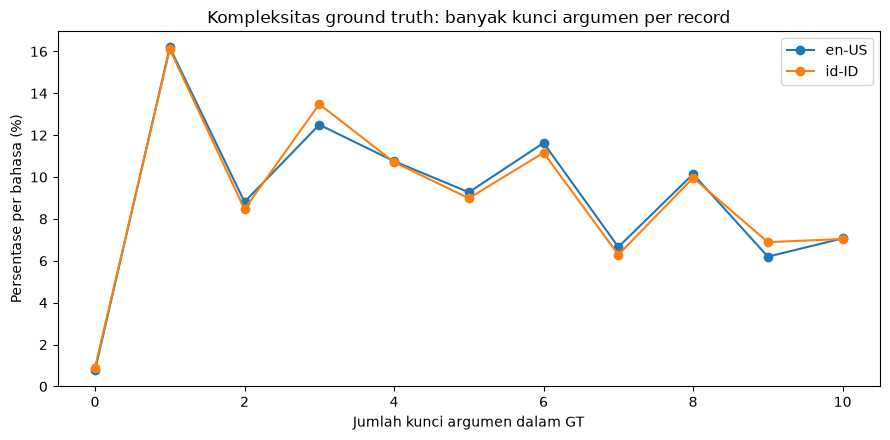

Audit khusus record yang pernah memicu warning ID 10061 (jika ada):


,language_code,row_key,record_id,gt_function_count,argument_keys,argument_values,nonempty_values,empty_string_values,empty_list_keys,scalar_keys,nonstring_values,missing_required_keys,out_of_schema_keys,unavailable_gt_functions,invalid_gt_parameter_objects
1211,en-US,en-US:0001212,10061,1,6,6,1,5,0,0,0,0,1,0,0
2777,id-ID,id-ID:0000826,10061,1,6,6,1,5,0,0,0,0,1,0,0


,language_code,row_key,record_id,function_name,issue_type,argument_name,detail
0,en-US,en-US:0001212,10061,cooking.recipe,gt_argument_out_of_schema,meal_type,Nama parameter GT tidak ada pada properties fu...
1,id-ID,id-ID:0000826,10061,cooking.recipe,gt_argument_out_of_schema,meal_type,Nama parameter GT tidak ada pada properties fu...


In [36]:
# Ringkasan metrik per bahasa. Angka 'kosong' TIDAK disamakan dengan anotasi buruk.
arg_metrics = ["argument_keys", "argument_values", "nonempty_values", "empty_string_values"]
argument_summary_df = arg_complexity_df.groupby("language_code").agg(
    records=("row_key", "size"),
    mean_argument_keys=("argument_keys", "mean"),
    median_argument_keys=("argument_keys", "median"),
    p95_argument_keys=("argument_keys", lambda v: v.quantile(.95)),
    mean_nonempty_values=("nonempty_values", "mean"),
    records_with_empty_string=("empty_string_values", lambda v: int(v.gt(0).sum())),
    records_with_empty_list=("empty_list_keys", lambda v: int(v.gt(0).sum())),
    records_with_out_of_schema=("out_of_schema_keys", lambda v: int(v.gt(0).sum())),
    records_with_missing_required=("missing_required_keys", lambda v: int(v.gt(0).sum())),
    records_with_nonstring_values=("nonstring_values", lambda v: int(v.gt(0).sum())),
).reset_index()
argument_summary_df = argument_summary_df.round(3)
display(argument_summary_df)

argument_function_summary_df = (per_function_argument_df
    .groupby(["language_code", "function_name"])
    .agg(records=("row_key", "size"),
         mean_argument_keys=("argument_keys", "mean"),
         mean_nonempty_values=("nonempty_values", "mean"),
         schema_warning_records=("out_of_schema_keys", lambda v: int(v.gt(0).sum())))
    .reset_index().round(3))
print("Fungsi yang rata-rata memerlukan banyak kunci argumen:")
display(argument_function_summary_df.sort_values(
    ["mean_argument_keys", "records"], ascending=[False, False]).head(15))

fig, ax = plt.subplots(figsize=(9, 4.5))
for lang in LANGUAGES:
    vals = arg_complexity_df.loc[arg_complexity_df.language_code.eq(lang), "argument_keys"]
    freq = vals.value_counts(normalize=True).sort_index()
    ax.plot(freq.index, freq.values * 100, marker="o", label=lang)
ax.set(xlabel="Jumlah kunci argumen dalam GT", ylabel="Persentase per bahasa (%)",
       title="Kompleksitas ground truth: banyak kunci argumen per record")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "gt_argument_key_distribution.png", dpi=180)
plt.show(); plt.close(fig)

print("Audit khusus record yang pernah memicu warning ID 10061 (jika ada):")
warning_10061 = arg_complexity_df.loc[arg_complexity_df.record_id.eq("10061")]
display(warning_10061.drop(columns=["question"]) if len(warning_10061) else warning_10061)
display(arg_issue_df.loc[arg_issue_df.record_id.eq("10061")])


### **12B · Verifikasi Manual Variasi Bahasa**

---

Hasil deteksi awal menunjukkan 172 kandidat bahasa Inggris dan 1 kandidat bahasa Indonesia. Angka tersebut belum menunjukkan jumlah sebenarnya dari data informal, slang, atau typo karena masih berdasarkan heuristik.

Sampel untuk pemeriksaan manual dipilih berdasarkan hasil deteksi, fungsi yang jarang muncul, dan variasi panjang teks. Sampel ini tidak digunakan untuk memperkirakan persentase variasi bahasa dalam keseluruhan dataset.

Pelabelan dilakukan melalui CSV dengan kategori berikut:

- `register_label`: formal, neutral, informal, atau uncertain.
- `slang_present`, `typo_present`, `abbreviation_present`, `code_switch_present`: yes, no, atau uncertain.
- `meaning_clear`: apakah maksud perintah dapat dipahami.
- `annotation_confidence`: tingkat keyakinan penilai (high, medium, low).

Perbedaan slang, bahasa informal, typo, dan singkatan perlu ditentukan secara jelas sebelum pelabelan. Jika memungkinkan, sebagian sampel diperiksa oleh dua penilai untuk meningkatkan konsistensi hasil.

File anotasi yang sudah diisi tidak akan ditimpa saat notebook dijalankan ulang.


In [37]:
# Pemilihan contoh review deterministik per strata; deduplikasi kelompok sumber.
# Tidak menambahkan 'label otomatis'.
review_work = eda_df.copy()
review_work["review_rare_function"] = review_work.gt_names.map(
    review_work.gt_names.value_counts()).fillna(0).le(12)
review_work["review_long_text"] = False
for lang in LANGUAGES:
    is_lang = review_work.language_code.eq(lang)
    cutoff = review_work.loc[is_lang, "question_word_count"].quantile(.95)
    review_work.loc[is_lang, "review_long_text"] = review_work.loc[is_lang, "question_word_count"].ge(cutoff)

review_picks = []
review_sampling_plan = [
    ("heuristic_positive", lambda sub: sub.any_candidate_signal, 26),
    ("heuristic_negative", lambda sub: ~sub.any_candidate_signal, 26),
    ("rare_target_function", lambda sub: sub.review_rare_function, 12),
    ("long_input", lambda sub: sub.review_long_text, 8),
]
for language_idx, lang in enumerate(LANGUAGES):
    sub = review_work.loc[review_work.language_code.eq(lang)].copy()
    seen = set()
    for stratum_idx, (stratum, predicate, quota) in enumerate(review_sampling_plan):
        pool = sub.loc[predicate(sub)].sample(frac=1, random_state=RANDOM_SEED + 17 * language_idx + stratum_idx)
        accepted = 0
        for _, rec in pool.iterrows():
            # Hindari mereview dua teks identik dari bahasa yang sama.
            group_id = (lang, rec["question_cmp"] or rec["row_key"])
            if group_id in seen:
                continue
            seen.add(group_id)
            review_picks.append({"row_key": rec["row_key"], "selection_stratum": stratum})
            accepted += 1
            if accepted >= quota:
                break

picks = pd.DataFrame(review_picks, columns=["row_key", "selection_stratum"])
review_ext = picks.merge(review_work, on="row_key", how="left", validate="one_to_one")
cols = ["row_key", "record_id", "language_code", "question", "gt_names",
        "selection_stratum", "any_candidate_signal", "lexicon_hits",
        "question_word_count", "proposed_leakage_group"]
language_review_extended_df = review_ext[cols].copy()
for field in ["register_label", "slang_present", "typo_present",
              "abbreviation_present", "code_switch_present", "meaning_clear",
              "annotation_confidence", "annotator_id", "review_notes"]:
    language_review_extended_df[field] = ""

sampling_summary_df = (language_review_extended_df
    .groupby(["language_code", "selection_stratum"])
    .size().rename("n_selected").reset_index())
print("Sampel kandidat untuk tinjauan manusia:", len(language_review_extended_df))
display(sampling_summary_df)
display(language_review_extended_df.head(8))

Sampel kandidat untuk tinjauan manusia: 119


,language_code,selection_stratum,n_selected
0,en-US,heuristic_negative,26
1,en-US,heuristic_positive,26
2,en-US,long_input,8
3,en-US,rare_target_function,12
4,id-ID,heuristic_negative,26
5,id-ID,heuristic_positive,1
6,id-ID,long_input,8
7,id-ID,rare_target_function,12


,row_key,record_id,language_code,question,gt_names,selection_stratum,any_candidate_signal,lexicon_hits,question_word_count,proposed_leakage_group,register_label,slang_present,typo_present,abbreviation_present,code_switch_present,meaning_clear,annotation_confidence,annotator_id,review_notes
0,en-US:0000462,3605,en-US,what's the latest news on c. n. n.,news.query,heuristic_positive,True,,8,en-US:0000462,,,,,,,,,
1,en-US:0000385,3020,en-US,does louie's do take out,takeaway.query,heuristic_positive,True,,5,en-US:0000385,,,,,,,,,
2,en-US:0000938,7876,en-US,what's been happening for the last two months,news.query,heuristic_positive,True,,8,en-US:0000938,,,,,,,,,
3,en-US:0000645,4973,en-US,olly play i can't feel my face,play.music,heuristic_positive,True,,7,en-US:0000645,,,,,,,,,
4,en-US:0000866,7170,en-US,it's my mother's birthday today send me a noti...,calendar.set,heuristic_positive,True,,14,en-US:0000866,,,,,,,,,
5,en-US:0000410,3214,en-US,what is the current state of the investigation...,news.query,heuristic_positive,True,,13,en-US:0000410,,,,,,,,,
6,en-US:0001238,10268,en-US,let's play global thermonuclear war,play.game,heuristic_positive,True,,5,en-US:0001238,,,,,,,,,
7,en-US:0000932,7768,en-US,please add practice on feb four at king's park...,calendar.set,heuristic_positive,True,,13,en-US:0000932,,,,,,,,,



### **12C · Pemeriksaan Kesepadanan Data Inggris dan Indonesia**

---

Data Bahasa Inggris dan Indonesia dengan ID yang sama belum tentu memiliki makna atau argumen `gt` yang sepenuhnya setara. Perbedaan nilai argumen dapat terjadi karena penerjemahan atau penyesuaian konteks bahasa.

Pemeriksaan otomatis membandingkan nama fungsi, kunci argumen, dan nilai argumen dalam `gt`. Hasilnya digunakan untuk menentukan data yang perlu ditinjau, bukan langsung dianggap benar atau salah.

Kesepadanan makna perintah, fungsi, dan argumen tetap perlu diverifikasi secara manual sebelum data digunakan untuk perbandingan performa model antarbahasa.


In [38]:
def _gt_shape(signature):
    try:
        parsed = json.loads(signature)
        if not isinstance(parsed, dict):
            return tuple(), None
        keys = tuple(sorted(
            (str(fn), str(arg))
            for fn, params in parsed.items()
            if isinstance(params, dict)
            for arg in params.keys()
        ))
        return keys, parsed
    except (ValueError, TypeError):
        return tuple(), None

pair_shape_rows = []
for rec in pairs_df.itertuples(index=False):
    en_shape, en_gt = _gt_shape(rec.gt_signature_en)
    id_shape, id_gt = _gt_shape(rec.gt_signature_id)
    if not rec.same_function_names:
        kind = "different_function_names"
    elif rec.same_complete_gt:
        kind = "identical_complete_gt"
    elif en_gt is None or id_gt is None:
        kind = "gt_unreadable"
    elif en_shape != id_shape:
        kind = "different_argument_keys"
    else:
        kind = "same_keys_different_values"
    pair_shape_rows.append({"record_id": rec.record_id, "gt_comparison_stratum": kind,
                            "same_argument_key_sets": bool(en_shape == id_shape)})

pair_shape_df = pd.DataFrame(pair_shape_rows, columns=[
    "record_id", "gt_comparison_stratum", "same_argument_key_sets"
])
paired_extended_df = pairs_df.merge(pair_shape_df, on="record_id", how="left", validate="one_to_one")
pair_comparison_summary_df = (paired_extended_df.gt_comparison_stratum
    .value_counts().rename_axis("gt_comparison_stratum")
    .rename("n_pairs").reset_index())
display(pair_comparison_summary_df)
print("Catatan: beda nilai/kunci argumen GT tidak otomatis berarti terjemahan salah.")

# Stratifikasi review: seluruh kelompok dengan prioritas kasus sulit, sisanya sampling deterministik.
pair_quotas = {
    "different_function_names": 15,
    "different_argument_keys": 22,
    "same_keys_different_values": 22,
    "identical_complete_gt": 15,
    "gt_unreadable": 15,
}
picked_pairs = []
for i, (stratum, quota) in enumerate(pair_quotas.items()):
    group = paired_extended_df.loc[paired_extended_df.gt_comparison_stratum.eq(stratum)]
    if len(group):
        picked_pairs.append(group.sample(n=min(quota, len(group)), random_state=RANDOM_SEED + i))
pair_review_extended_df = (pd.concat(picked_pairs, ignore_index=True)
    if picked_pairs else paired_extended_df.head(0).copy())
# Sampel eksplisit kasus penting yang pernah muncul di data inspection / EDA.
critical_pair_ids = {"334", "2690", "448", "10061"}
extra = paired_extended_df.loc[paired_extended_df.record_id.isin(critical_pair_ids)]
if len(extra):
    pair_review_extended_df = pd.concat([pair_review_extended_df, extra], ignore_index=True)
pair_review_extended_df = pair_review_extended_df.drop_duplicates(subset="record_id")

pair_template_cols = ["record_id", "row_key_en", "row_key_id", "question_en", "question_id",
    "gt_names_en", "gt_names_id", "gt_signature_en", "gt_signature_id",
    "same_function_names", "gt_comparison_stratum", "same_argument_key_sets"]
pair_review_extended_df = pair_review_extended_df[pair_template_cols].copy()
for field in ["question_meaning_equivalent", "target_function_equivalent",
              "argument_semantics_equivalent", "expected_localization_difference",
              "suitable_for_paired_evaluation", "annotation_confidence", "annotator_id", "review_notes"]:
    pair_review_extended_df[field] = ""
print("Calon pasangan untuk audit manusia:", len(pair_review_extended_df))
display(pair_review_extended_df.head(8))

,gt_comparison_stratum,n_pairs
0,same_keys_different_values,966
1,identical_complete_gt,367


Catatan: beda nilai/kunci argumen GT tidak otomatis berarti terjemahan salah.
Calon pasangan untuk audit manusia: 41


,record_id,row_key_en,row_key_id,question_en,question_id,gt_names_en,gt_names_id,gt_signature_en,gt_signature_id,same_function_names,gt_comparison_stratum,same_argument_key_sets,question_meaning_equivalent,target_function_equivalent,argument_semantics_equivalent,expected_localization_difference,suitable_for_paired_evaluation,annotation_confidence,annotator_id,review_notes
0,891,en-US:0000116,id-ID:0000083,play some christian music,putar beberapa musik islami,play.music,play.music,"{""play.music"":{""artist_name"":[""""],""device_type...","{""play.music"":{""artist_name"":[""""],""device_type...",True,same_keys_different_values,True,,,,,,,,
1,2423,en-US:0000315,id-ID:0000217,please give me todays forecast for new york city,berikan saya perkiraan cuaca hari ini di jakarta,weather.query,weather.query,"{""weather.query"":{""date"":[""todays""],""event_nam...","{""weather.query"":{""date"":[""hari ini""],""event_n...",True,same_keys_different_values,True,,,,,,,,
2,10827,en-US:0001303,id-ID:0000886,delete list for groceries,hapus daftar dari bahan makanan sehari hari,lists.remove,lists.remove,"{""lists.remove"":{""date"":[""""],""list_name"":[""gro...","{""lists.remove"":{""date"":[""""],""list_name"":[""bah...",True,same_keys_different_values,True,,,,,,,,
3,8469,en-US:0001008,id-ID:0000689,what is scheduled on my calendar today,apa yang ada pada kalender saya hari ini,calendar.query,calendar.query,"{""calendar.query"":{""date"":[""today""],""event_nam...","{""calendar.query"":{""date"":[""hari ini""],""event_...",True,same_keys_different_values,True,,,,,,,,
4,14767,en-US:0001740,id-ID:0001168,how would you describe a ball,bagaimana kamu mendeskripsikan bola,qa.definition,qa.definition,"{""qa.definition"":{""definition_word"":[""ball""]}}","{""qa.definition"":{""definition_word"":[""bola""]}}",True,same_keys_different_values,True,,,,,,,,
5,8559,en-US:0001017,id-ID:0000693,do i have anything scheduled for today,apakah saya ada jadwal hari ini,calendar.query,calendar.query,"{""calendar.query"":{""date"":[""today""],""event_nam...","{""calendar.query"":{""date"":[""hari ini""],""event_...",True,same_keys_different_values,True,,,,,,,,
6,9897,en-US:0001188,id-ID:0000809,playback tom clancy splinter cell,mulai tom clancy splinter cell,play.audiobook,play.audiobook,"{""play.audiobook"":{""audiobook_author"":[""tom cl...","{""play.audiobook"":{""audiobook_author"":[""tom cl...",True,same_keys_different_values,True,,,,,,,,
7,2330,en-US:0000300,id-ID:0000209,display the local time of london at this moment,tampilkan waktu setempat di bandung saat ini,datetime.query,datetime.query,"{""datetime.query"":{""date"":[""""],""place_name"":[""...","{""datetime.query"":{""date"":[""""],""place_name"":[""...",True,same_keys_different_values,True,,,,,,,,



### **12D · Penyimpanan Hasil dan Review Sebelum Preprocessing**

---

Hasil analisis otomatis dapat diperbarui setiap kali notebook dijalankan. File anotasi manual yang sudah tersedia tidak akan ditimpa agar hasil pemeriksaan sebelumnya tetap tersimpan.

Jika anotasi sudah diisi, jumlah data pada setiap kategori akan ditampilkan saat notebook dijalankan kembali.

Template yang masih kosong bukan berarti data tidak mengandung slang atau typo. Hasil anotasi juga belum dapat digunakan untuk menentukan persentase variasi bahasa dalam keseluruhan dataset karena sampel tidak dipilih secara acak dan proporsional.


In [39]:
# Ekspor statistik & daftar kandidat boleh di-refresh karena berasal dari kode otomatis.
auto_exports = {
    "gt_argument_complexity_records.csv": arg_complexity_df,
    "gt_argument_complexity_summary.csv": argument_summary_df,
    "gt_argument_complexity_by_function.csv": argument_function_summary_df,
    "gt_schema_issue_candidates.csv": arg_issue_df,
    "gt_argument_function_records.csv": per_function_argument_df,
    "language_review_sampling_summary.csv": sampling_summary_df,
    "pair_gt_comparison_summary.csv": pair_comparison_summary_df,
    "pair_gt_comparison_all.csv": paired_extended_df[[
        "record_id", "gt_comparison_stratum", "same_argument_key_sets",
        "same_function_names", "same_complete_gt"]],
}
for fname, frame in auto_exports.items():
    frame.to_csv(OUTPUT_DIR / fname, index=False, encoding="utf-8-sig")

review_files = {
    "manual_language_extended_review.csv": language_review_extended_df,
    "manual_translation_extended_review.csv": pair_review_extended_df,
}
for fname, frame in review_files.items():
    outpath = OUTPUT_DIR / fname
    if outpath.exists():
        print(f"TIDAK DITIMPA (menjaga anotasi manual): {outpath.name}")
    else:
        frame.to_csv(outpath, index=False, encoding="utf-8-sig")
        print(f"Template review baru dibuat: {outpath.name}")

for fname, label_columns in [
    ("manual_language_extended_review.csv", ["register_label", "slang_present", "typo_present",
         "abbreviation_present", "code_switch_present", "meaning_clear"]),
    ("manual_translation_extended_review.csv", ["question_meaning_equivalent",
        "target_function_equivalent", "argument_semantics_equivalent",
        "suitable_for_paired_evaluation"]),
]:
    saved = pd.read_csv(OUTPUT_DIR / fname, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    if all(c in saved.columns for c in label_columns):
        done = saved[label_columns].apply(lambda col: col.astype(str).str.strip().ne(""))
        completely_reviewed = int(done.all(axis=1).sum())
        print(f"{fname}: {completely_reviewed}/{len(saved)} baris sudah mengisi semua kolom label inti")
    else:
        print(f"PERHATIAN: {fname} punya format kolom berbeda; pastikan anotasi manual tersimpan aman.")

TIDAK DITIMPA (menjaga anotasi manual): manual_language_extended_review.csv
TIDAK DITIMPA (menjaga anotasi manual): manual_translation_extended_review.csv
manual_language_extended_review.csv: 0/119 baris sudah mengisi semua kolom label inti
manual_translation_extended_review.csv: 0/41 baris sudah mengisi semua kolom label inti


#### Keputusan akhir sebelum preprocessing

1. **Dokumentasi EDA otomatis** dianggap lengkap setelah sel tanpa error, hasil audit skema dicocokkan dengan Data Inspection, dan jumlah file konsisten.
2. **Review manusia masih terbuka** selama template review belum diberi label. Tidak perlu menunda seluruh preprocessing yang bersifat teknis, tetapi **jangan mendeklarasikan prevalensi slang/typo atau pasangan bilingual valid** sebelum anotasi selesai.
3. **Audit kasus:** `cooking.recipe` ID `10061`, dua kelompok pertanyaan Indonesia dengan GT berbeda, serta pasangan dengan perbedaan entitas/waktu penting sebelum menetapkan gold standard final.
4. **Langkah berikut:** `preprocessing.ipynb` untuk pemformatan, penanganan kasus beralasan, dan rencana split grup anti-*leakage*. Setiap keputusan penghapusan/perbaikan harus ditulis dalam *decision log*, bukan otomatis berdasarkan flag.
5. **Batasan:** EDA tidak mengukur performa model dan tidak membuktikan sistem melakukan *agentic multi-step execution*. Benchmark saat ini berfokus pada *function selection* dan *argument extraction*.


## **13 · Penyimpanan Hasil EDA**

---

Seluruh hasil analisis disimpan di `results/exploratory_analysis/` tanpa mengubah data asli di `data/raw`.

File `records_eda.csv` berisi teks perintah asli dan metadata ground truth, tanpa menyimpan ulang seluruh katalog fungsi.

Informasi sumber data, versi library, seed, dan hasil pemeriksaan masalah juga disimpan agar analisis dapat dijalankan ulang dengan hasil yang konsisten.


In [40]:
exports={
    "file_manifest.csv":manifest_df,
    "file_problems.csv":file_problems_df,
    "dataset_profile.csv":profile_df,
    "categories.csv":category_counts,
    "gt_calls_per_record.csv":call_counts,
    "text_lengths.csv":length_df,
    "function_frequency.csv":function_df,
    "function_summary.csv":function_summary_df,
    "domain_distribution.csv":domains,
    "language_cohort_distribution.csv":cohort_df,
    "function_by_cohort.csv":function_cohort_df,
    "offered_function_catalog_variants.csv":catalog_df,
    "lexical_summary.csv":lexical_df,
    "language_signal_candidates.csv":signal_summary_df,
    "duplicate_exact_groups.csv":dup_exact_df,
    "duplicate_normalized_groups.csv":dup_normalized_df,
    "duplicate_conflicts_review.csv":conflicting_dup_df,
    "cross_language_pairs.csv":pairs_df[["record_id","row_key_en","row_key_id",
                                       "question_en","question_id","gt_names_en","gt_names_id",
                                       "same_function_names","same_complete_gt"]] if len(pairs_df) else pairs_df,
    "leakage_group_summary.csv":leakage_summary_df,
    "records_eda.csv":eda_df.drop(columns=["question_cmp", "gt_signature"]),
    "manual_language_review_template.csv":review_template_df,
    "manual_translation_review_template.csv":pair_review_df,
}
for filename,frame in exports.items():
    target = OUTPUT_DIR / filename
    if filename in {"manual_language_review_template.csv", "manual_translation_review_template.csv"} and target.exists():
        print(f"Menjaga review manual yang sudah ada: {filename} (tidak ditimpa)")
        continue
    frame.to_csv(target,index=False,encoding="utf-8-sig")

metadata={
    "project":"KP Agentic AI + LLM",
    "stage":"exploratory_data_analysis",
    "created_utc":datetime.now(timezone.utc).isoformat(),
    "source":SOURCE_URL,
    "dataset_folder":DATASET_FOLDER,
    "languages":list(LANGUAGES),
    "python":sys.version.split()[0],
    "pandas":pd.__version__,
    "matplotlib":plt.matplotlib.__version__,
    "numpy":np.__version__,
    "random_seed":RANDOM_SEED,
    "raw_files":manifest_rows,
    "raw_file_problems_count":len(file_problems_df),
    "source_file_lines":{lang:{key:int(file_summary[(lang,key)]) for key in ("input_lines","golden_lines")}
                         for lang in LANGUAGES},
    "analysed_records":int(len(eda_df)),
    "note":"Heuristic signals are NOT verified slang/informal/typo labels; no preprocessing or split done.",
}
(OUTPUT_DIR/"eda_metadata.json").write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding="utf-8")
print("Hasil EDA disimpan di",OUTPUT_DIR)
print("Jumlah CSV:",len(exports),"| Grafik PNG:",len(list(OUTPUT_DIR.glob("*.png"))))

Menjaga review manual yang sudah ada: manual_language_review_template.csv (tidak ditimpa)
Menjaga review manual yang sudah ada: manual_translation_review_template.csv (tidak ditimpa)
Hasil EDA disimpan di D:\KP-Agentic-AI\results\exploratory_analysis
Jumlah CSV: 22 | Grafik PNG: 9



## **14 · Kesimpulan Hasil EDA**

---

### **Ringkasan Hasil Analisis**


In [42]:

import pandas as pd
from IPython.display import display

# Ringkasan hasil EDA
hasil_eda = pd.DataFrame([
    {
        "Indikator": "Jumlah data",
        "Hasil": ", ".join(
            f"{lang}: {eda_df.language_code.eq(lang).sum():,}"
            for lang in LANGUAGES
        )
    },
    {
        "Indikator": "Fungsi target",
        "Hasil": ", ".join(
            f"{row.language_code}: {int(row.unique_functions)} fungsi"
            for row in function_summary_df.itertuples(index=False)
        )
    },
    {
        "Indikator": "Kualitas data",
        "Hasil": (
            f"{len(file_problems_df)} masalah pembacaan/pasangan JSON; "
            f"{(~eda_df.input_golden_equal).sum()} input–golden tidak cocok"
        )
    },
    {
        "Indikator": "Duplikasi pertanyaan",
        "Hasil": (
            f"{len(dup_normalized_df)} grup duplikat; "
            f"{len(conflicting_dup_df)} grup dengan GT berbeda"
        )
    },
    {
        "Indikator": "Pasangan antarbahasa",
        "Hasil": f"{len(pairs_df)} ID sama"
    },
    {
        "Indikator": "Kandidat variasi bahasa",
        "Hasil": ", ".join(
            f"{lang}: {int(eda_df.loc[eda_df.language_code.eq(lang), 'any_candidate_signal'].sum())}"
            for lang in LANGUAGES
        )
    },
    {
        "Indikator": "Warning skema GT",
        "Hasil": (
            f"{len(arg_issue_df)} warning"
            if "arg_issue_df" in globals()
            else "Belum tersedia (jalankan analisis 12A)"
        )
    },
    {
        "Indikator": "Grup anti-leakage",
        "Hasil": f"{len(size_series)} grup"
    }
])


display(hasil_eda)



,Indikator,Hasil
0,Jumlah data,"en-US: 1,952, id-ID: 1,335"
1,Fungsi target,"en-US: 55 fungsi, id-ID: 55 fungsi"
2,Kualitas data,0 masalah pembacaan/pasangan JSON; 0 input–gol...
3,Duplikasi pertanyaan,22 grup duplikat; 2 grup dengan GT berbeda
4,Pasangan antarbahasa,1333 ID sama
5,Kandidat variasi bahasa,"en-US: 172, id-ID: 1"
6,Warning skema GT,2 warning
7,Grup anti-leakage,1925 grup



### **Insight dari Hasil EDA**

---

| Temuan | Insight |
|---|---|
| Jumlah data | Bahasa Inggris memiliki 1.952 data dan Bahasa Indonesia 1.335 data. Perbedaan jumlah data perlu diperhatikan saat evaluasi model. |
| Fungsi target | Kedua bahasa memiliki 55 fungsi target, tetapi distribusi jumlah data per fungsi tetap perlu diperhatikan. |
| Kualitas data | Tidak ditemukan masalah pembacaan JSON maupun ketidaksesuaian input dengan golden. |
| Duplikasi | Dari 22 grup pertanyaan duplikat, terdapat 2 grup dengan GT berbeda yang perlu diperiksa. |
| Pasangan antarbahasa | Terdapat 1.333 ID yang sama, tetapi kesepadanan maknanya belum dipastikan. |
| Variasi bahasa | Terdapat 172 kandidat pada Bahasa Inggris dan 1 pada Bahasa Indonesia. Angka ini hanya hasil deteksi awal, bukan jumlah slang atau typo yang sebenarnya. |
| Kesesuaian skema | Ditemukan 2 warning yang perlu diperiksa sebelum evaluasi model. |
| Data leakage | Sebanyak 1.925 grup data terbentuk untuk membantu mencegah kebocoran data saat pembagian dataset. |

### **Langkah Selanjutnya**

1. Memeriksa 2 grup duplikasi dengan GT berbeda dan 2 warning skema.
2. Memverifikasi sampel variasi bahasa dan kesepadanan pasangan Inggris–Indonesia.
3. Melanjutkan preprocessing dan pembagian dataset berdasarkan grup anti-leakage.
4. Menjalankan baseline model pada Bahasa Inggris dan Indonesia, kemudian mengevaluasi pengaruh variasi bahasa.
